In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/cleaned/adult_income_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (48813, 20)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,source_split,high_income,age_group,hours_group,net_capital
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train,0,36-45,21-40,2174
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train,0,46-55,0-20,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train,0,36-45,21-40,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,train,0,46-55,21-40,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,train,0,26-35,21-40,0


In [3]:
print(df["high_income"].value_counts())
print()
print(df["high_income"].value_counts(normalize=True) * 100)

high_income
0    37128
1    11685
Name: count, dtype: int64

high_income
0    76.061705
1    23.938295
Name: proportion, dtype: float64


In [4]:

# Separate input features (X) and target (y)

X = df.drop(
    columns=["income", "high_income", "source_split"]
)

y = df["high_income"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)


X shape: (48813, 17)
y shape: (48813,)

Features:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'age_group', 'hours_group', 'net_capital']

Target:
high_income


In [5]:
print(X.head())
print("\nData types:")
print(X.dtypes)

   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country age_group  \
0          2174             0              40  United-States     36-45   
1             0             0     

In [6]:

# Find categorical columns

categorical_columns = X.select_dtypes(include="object").columns.tolist()

print("Categorical columns:")
print(categorical_columns)


# Convert categorical columns into numerical columns

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

# Convert True/False values into 0/1

X = X.astype(float)

print("\nEncoding completed!")
print("New X shape:", X.shape)

print("\nFirst 5 rows:")
print(X.head())


C:\Users\asusvivobook\AppData\Local\Temp\ipykernel_10536\4015334020.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns.tolist()


Categorical columns:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'age_group', 'hours_group']

Encoding completed!
New X shape: (48813, 109)

First 5 rows:
    age    fnlwgt  education_num  capital_gain  capital_loss  hours_per_week  \
0  39.0   77516.0           13.0        2174.0           0.0            40.0   
1  50.0   83311.0           13.0           0.0           0.0            13.0   
2  38.0  215646.0            9.0           0.0           0.0            40.0   
3  53.0  234721.0            7.0           0.0           0.0            40.0   
4  28.0  338409.0           13.0           0.0           0.0            40.0   

   net_capital  workclass_Local-gov  workclass_Never-worked  \
0       2174.0                  0.0                     0.0   
1          0.0                  0.0                     0.0   
2          0.0                  0.0                     0.0   
3          0.0                  0.0             

In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split successfully!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



Data split successfully!
X_train: (39050, 109)
X_test: (9763, 109)
y_train: (39050,)
y_test: (9763,)


In [8]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler on test data
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully!")

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)



Scaling completed successfully!
X_train_scaled shape: (39050, 109)
X_test_scaled shape: (9763, 109)


In [9]:
scaler.fit_transform(X_train)

array([[-0.99391   ,  0.61851038,  1.13553768, ...,  0.79338492,
        -0.59555   , -0.18857837],
       [-0.11799934,  0.59523147, -0.03117201, ..., -1.26042225,
         1.67912014, -0.18857837],
       [ 0.17397089, -0.71044363,  1.91334414, ..., -1.26042225,
         1.67912014, -0.18857837],
       ...,
       [ 0.17397089, -0.76608475, -0.03117201, ...,  0.79338492,
        -0.59555   , -0.18857837],
       [-0.70193978,  1.52775548,  1.13553768, ..., -1.26042225,
         1.67912014, -0.18857837],
       [-1.28588022, -0.76602815, -0.03117201, ...,  0.79338492,
        -0.59555   , -0.18857837]], shape=(39050, 109))

In [10]:
scaler.transform(X_test)

array([[-1.06690256, -1.51208509,  1.13553768, ...,  0.79338492,
        -0.59555   , -0.18857837],
       [ 0.68491878, -0.51288418, -0.03117201, ...,  0.79338492,
        -0.59555   , -0.18857837],
       [-1.21288767,  1.17549693,  1.13553768, ...,  0.79338492,
        -0.59555   , -0.18857837],
       ...,
       [ 2.36374755,  1.07490149,  1.52444091, ..., -1.26042225,
        -0.59555   , -0.18857837],
       [-0.84792489, -0.15050477,  1.13553768, ..., -1.26042225,
         1.67912014, -0.18857837],
       [-0.55595467,  0.56564236, -0.42007524, ...,  0.79338492,
        -0.59555   , -0.18857837]], shape=(9763, 109))

In [11]:

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")



Logistic Regression model trained successfully!


In [12]:

# Make predictions on the test data

y_pred = model.predict(X_test_scaled)

print("Predictions completed successfully!")

print("First 20 predictions:")
print(y_pred[:20])



Predictions completed successfully!
First 20 predictions:
[0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0]


In [13]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)



Model Evaluation
-------------------------
Accuracy : 0.8550650414831507
Precision: 0.7376288659793815
Recall   : 0.6123234916559692
F1 Score : 0.6691606266074351


In [14]:

from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)



Confusion Matrix:
[[6917  509]
 [ 906 1431]]


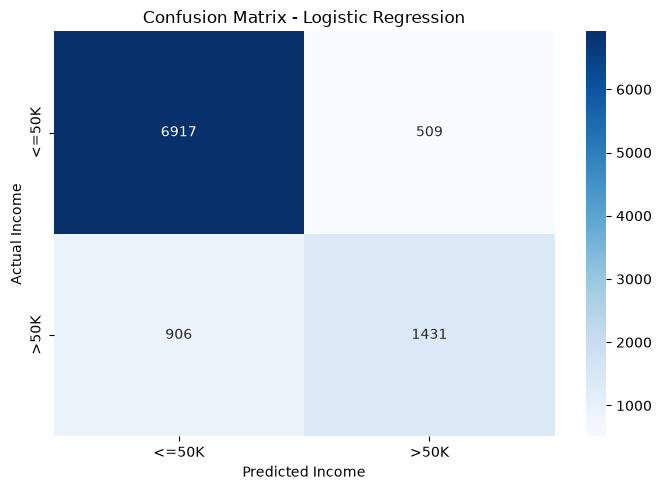

In [15]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()



In [16]:

import joblib
import json
import os

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the trained model
joblib.dump(model, "../models/income_model.pkl")

# Save the scaler
joblib.dump(scaler, "../models/scaler.pkl")

# Save feature names
metadata = {
    "model": "Logistic Regression",
    "target": "high_income",
    "features": X.columns.tolist()
}

with open("../models/model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Model files saved successfully!")



Model files saved successfully!


In [17]:
import os

print(os.listdir("../models"))

['income_model.pkl', 'model_metadata.json', 'scaler.pkl']


In [21]:

# Take one row from the test data
new_person = X_test.iloc[[0]]

print("New person shape:", new_person.shape)
print("Expected features:", X_train.shape[1])
print("New person features:", new_person.shape[1])

# Scale the new person's data
new_person_scaled = scaler.transform(new_person)

# Make prediction
prediction = model.predict(new_person_scaled)

print("\nPrediction:", prediction[0])

if prediction[0] == 1:
    print("Predicted Income: >50K")
else:
    print("Predicted Income: <=50K")


New person shape: (1, 109)
Expected features: 109
New person features: 109

Prediction: 0
Predicted Income: <=50K


In [22]:
X.iloc[[0]]

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,net_capital,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native_country_Vietnam,native_country_Yugoslavia,age_group_26-35,age_group_36-45,age_group_46-55,age_group_56-65,age_group_66+,hours_group_21-40,hours_group_41-60,hours_group_61+
0,39.0,77516.0,13.0,2174.0,0.0,40.0,2174.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [23]:
scaler.fit_transform(X_train)

array([[-0.99391   ,  0.61851038,  1.13553768, ...,  0.79338492,
        -0.59555   , -0.18857837],
       [-0.11799934,  0.59523147, -0.03117201, ..., -1.26042225,
         1.67912014, -0.18857837],
       [ 0.17397089, -0.71044363,  1.91334414, ..., -1.26042225,
         1.67912014, -0.18857837],
       ...,
       [ 0.17397089, -0.76608475, -0.03117201, ...,  0.79338492,
        -0.59555   , -0.18857837],
       [-0.70193978,  1.52775548,  1.13553768, ..., -1.26042225,
         1.67912014, -0.18857837],
       [-1.28588022, -0.76602815, -0.03117201, ...,  0.79338492,
        -0.59555   , -0.18857837]], shape=(39050, 109))

In [24]:

import os

model_path = "../models/income_model.pkl"
scaler_path = "../models/scaler.pkl"
metadata_path = "../models/model_metadata.json"

print("Model exists:", os.path.exists(model_path))
print("Scaler exists:", os.path.exists(scaler_path))
print("Metadata exists:", os.path.exists(metadata_path))



Model exists: True
Scaler exists: True
Metadata exists: True


In [25]:

import joblib

# Load saved model and scaler
loaded_model = joblib.load("../models/income_model.pkl")
loaded_scaler = joblib.load("../models/scaler.pkl")

# Take one test record
test_person = X_test.iloc[[0]]

# Scale the data
test_person_scaled = loaded_scaler.transform(test_person)

# Predict
loaded_prediction = loaded_model.predict(test_person_scaled)

print("Saved model loaded successfully!")
print("Prediction:", loaded_prediction[0])

if loaded_prediction[0] == 1:
    print("Predicted Income: >50K")
else:
    print("Predicted Income: <=50K")



Saved model loaded successfully!
Prediction: 0
Predicted Income: <=50K
